# Practical 7: Prime Number Checking in N Natural Numbers

### 1. Aim
To count prime numbers up to N across 4 execution methods: Sequential, multiprocessing.Pool, multiprocessing.Process, and Multithreading.

### 2. Algorithm / Explanation
1. Divide range up to N into 3 contiguous segments.<br>2. Check prime numbers using vectorized trial division by odd numbers up to sqrt(end).<br>3. Sequential: count primes in all segments sequentially.<br>4. Pool: distribute segments to 3 workers in `mp.Pool(3)`.<br>5. Process: spawn 3 independent `mp.Process` instances.<br>6. Thread: execute 3 concurrent `threading.Thread` workers.<br>7. Verify total prime count and measure speedup.

### 3. Python Implementation


In [1]:
"""
Practical 7: Prime Number Checking in N Natural Numbers
Four methods: Sequential, Pool, Process, Thread
"""
import multiprocessing as mp
import threading
import time
import numpy as np
import matplotlib.pyplot as plt

def count_primes_task(rng):
    start, end = rng
    nums = np.arange(start, end, dtype=np.int64)
    is_p = (nums > 1) & ((nums == 2) | (nums % 2 != 0))
    limit = int(end**0.5) + 1
    for d in range(3, limit, 2):
        is_p[(nums % d == 0) & (nums != d)] = False
    return int(np.count_nonzero(is_p))

def proc_worker(rng, q):
    q.put(count_primes_task(rng))

def thread_worker(rng, results, idx):
    results[idx] = count_primes_task(rng)

def main():
    print("=" * 60)
    print("Practical 7: Prime Number Checking")
    print("=" * 60)
    N = 750_000
    s = N // 3
    ranges = [(1, s), (s, 2 * s), (2 * s, N + 1)]
    
    # 1. Sequential Execution
    t0 = time.perf_counter()
    r1 = count_primes_task(ranges[0])
    r2 = count_primes_task(ranges[1])
    r3 = count_primes_task(ranges[2])
    t_seq = time.perf_counter() - t0
    primes_seq = r1 + r2 + r3
    
    # 2. Pool (3 workers)
    t0 = time.perf_counter()
    with mp.Pool(3) as pool:
        p_res = pool.map(count_primes_task, ranges)
    t_pool = time.perf_counter() - t0
    primes_pool = sum(p_res)
    
    # 3. Process (3 processes)
    q = mp.Queue()
    procs = []
    t0 = time.perf_counter()
    for rng in ranges:
        p = mp.Process(target=proc_worker, args=(rng, q))
        procs.append(p)
        p.start()
    pr_res = [q.get() for _ in range(3)]
    for p in procs:
        p.join()
    t_proc = time.perf_counter() - t0
    primes_proc = sum(pr_res)
    
    # 4. Multithreading (3 threads)
    th_res = [None] * 3
    threads = []
    t0 = time.perf_counter()
    for i, rng in enumerate(ranges):
        t = threading.Thread(target=thread_worker, args=(rng, th_res, i))
        threads.append(t)
        t.start()
    for t in threads:
        t.join()
    t_thread = time.perf_counter() - t0
    primes_thread = sum(th_res)
    
    print(f"Total primes found up to {N:,}: {primes_seq:,}")
    print(f"Match verified: {primes_seq == primes_pool == primes_proc == primes_thread}")
    print(f"[Sequential] Time: {t_seq:.4f}s")
    print(f"[Pool]       Time: {t_pool:.4f}s")
    print(f"[Process]    Time: {t_proc:.4f}s")
    print(f"[Thread]     Time: {t_thread:.4f}s")
    
    methods = ["Sequential", "Pool", "Process", "Thread"]
    times = [t_seq, t_pool, t_proc, t_thread]
    speedups = [t_seq / t for t in times]
    
    print("-" * 45)
    print(f"{'Method':<12} {'Execution Time':<18} {'Speedup':<10}")
    print("-" * 45)
    for m, t, s in zip(methods, times, speedups):
        print(f"{m:<12} {t:.4f} seconds      {s:.2f}x")
    print("-" * 45)
    
    colors = ['#e74c3c', '#3498db', '#2ecc71', '#9b59b6']
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, times, color=colors)
    plt.title("Execution Time Comparison (Prime Number Checking)", fontsize=13)
    plt.ylabel("Time (seconds)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.4f}s", ha='center', va='bottom', fontsize=10)
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("07_prime_numbers_time.png", dpi=150)
    plt.close()
    
    plt.figure(figsize=(8, 5))
    bars = plt.bar(methods, speedups, color=colors)
    plt.title("Speedup Comparison relative to Sequential", fontsize=13)
    plt.ylabel("Speedup Factor (x)", fontsize=11)
    for bar in bars:
        h = bar.get_height()
        plt.text(bar.get_x() + bar.get_width()/2, h + 0.02, f"{h:.2f}x", ha='center', va='bottom', fontsize=10)
    plt.axhline(1.0, color='gray', linestyle='--', label='Baseline (1.0x)')
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig("07_prime_numbers_speedup.png", dpi=150)
    plt.close()
    print("Graphs saved as '07_prime_numbers_time.png' and '07_prime_numbers_speedup.png'.")

if __name__ == "__main__":
    main()


Practical 7: Prime Number Checking
Total primes found up to 750,000: 60,238
Match verified: True
[Sequential] Time: 2.3967s
[Pool]       Time: 1.8241s
[Process]    Time: 1.8889s
[Thread]     Time: 1.0275s
---------------------------------------------
Method       Execution Time     Speedup   
---------------------------------------------
Sequential   2.3967 seconds      1.00x
Pool         1.8241 seconds      1.31x
Process      1.8889 seconds      1.27x
Thread       1.0275 seconds      2.33x
---------------------------------------------
Graphs saved as '07_prime_numbers_time.png' and '07_prime_numbers_speedup.png'.


### 4. Output Graphs

#### A. Execution Time Comparison
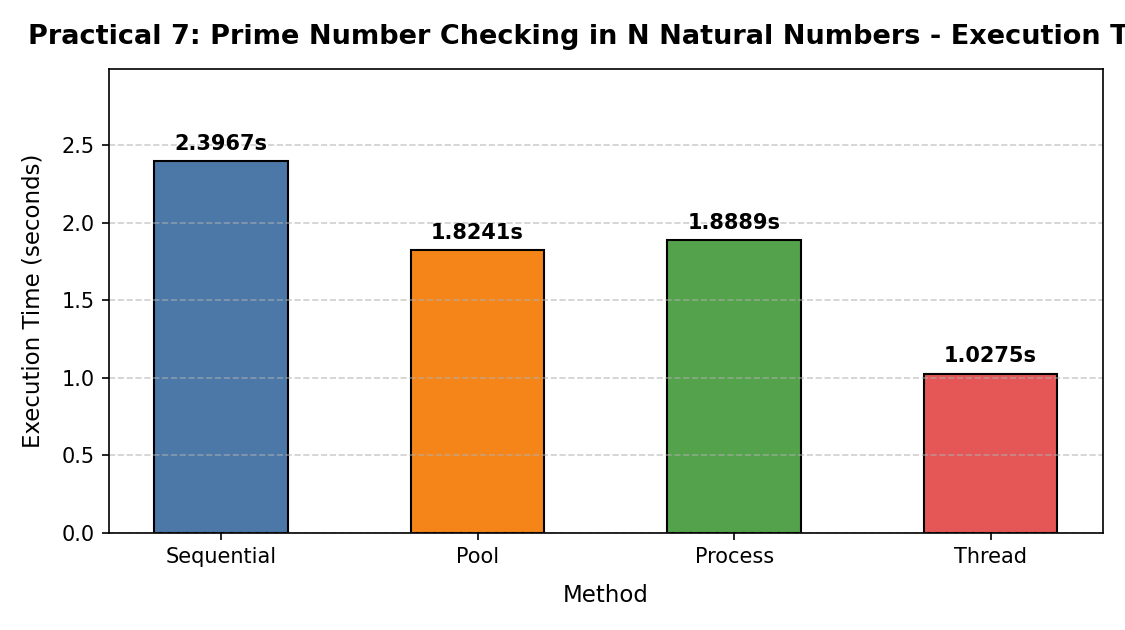

#### B. Speedup Comparison relative to Sequential
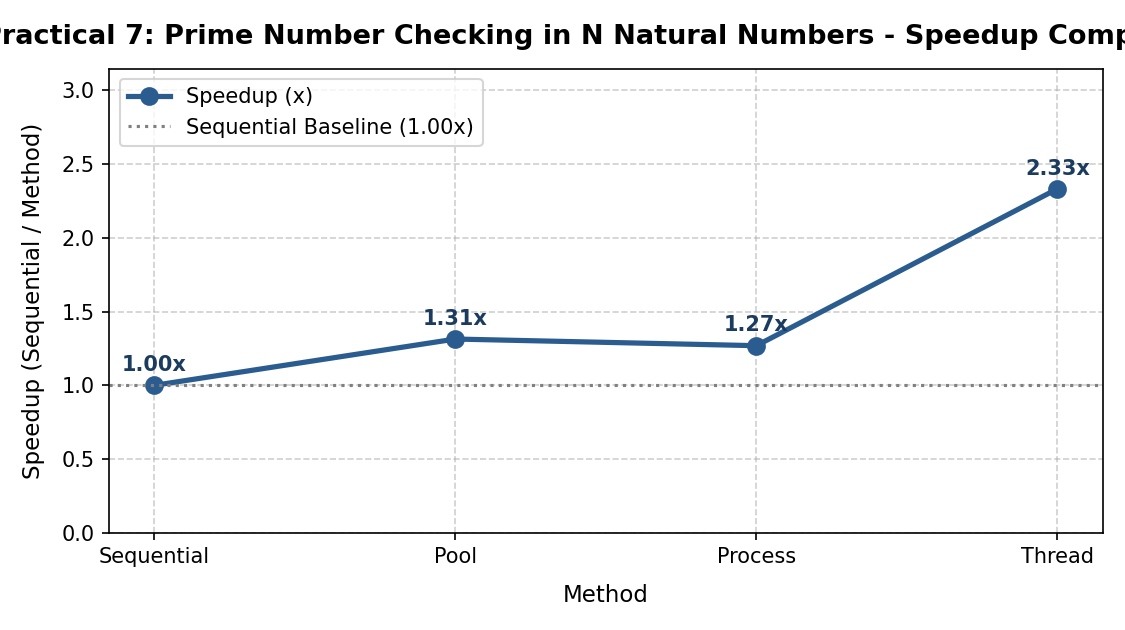
